In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from matplotlib.patches import Patch

In [5]:
# Load expression matrix and metadata
expr_matrix = pd.read_csv('./data/processed/GSE60052_expression_matrix.csv', index_col=0)
metadata = pd.read_csv('./data/metadata/GSE60052_metadata.csv', index_col=0)

print(expr_matrix.shape)
print(metadata['group'].value_counts())

(18362, 86)
group
SCLC      79
Normal     7
Name: count, dtype: int64


In [7]:
sclc_samples = metadata[metadata['group'] == 'SCLC'].index.tolist()
normal_samples = metadata[metadata['group'] == 'Normal'].index.tolist()

print(f"SCLC samples: {len(sclc_samples)}")
print(f"Normal samples: {len(normal_samples)}")

sclc_expr = expr_matrix[sclc_samples]
normal_expr = expr_matrix[normal_samples]

print(f"\nSCLC matrix: {sclc_expr.shape}")
print(f"Normal matrix: {normal_expr.shape}")

SCLC samples: 79
Normal samples: 7

SCLC matrix: (18362, 79)
Normal matrix: (18362, 7)


In [9]:
results = []

for gene in expr_matrix.index:
    sclc_values = sclc_expr.loc[gene].values
    normal_values = normal_expr.loc[gene].values
    
    stat, pval = mannwhitneyu(sclc_values, normal_values, alternative='two-sided')
    
    log2fc = np.mean(sclc_values) - np.mean(normal_values)
    
    results.append({
        'Gene': gene,
        'log2FC': log2fc,
        'pvalue': pval
    })

results_df = pd.DataFrame(results).set_index('Gene')

reject, pvals_corrected, _, _ = multipletests(results_df['pvalue'], method='fdr_bh')
results_df['padj'] = pvals_corrected

print(results_df.shape)
print(results_df.head())

(18362, 3)
         log2FC        pvalue      padj
Gene                                   
A1BG   0.337253  4.295453e-01  0.598682
A1CF  -0.480319  6.417604e-01  0.772575
A2M   -3.913485  3.457902e-07  0.000054
A2ML1  0.981405  2.993277e-01  0.478185
A2MP1 -1.509902  1.977554e-02  0.074700


In [11]:
sig_degs = results_df[(results_df['padj'] < 0.05) & (abs(results_df['log2FC']) >= 1)]
print(f"Total significant DEGs: {len(sig_degs)}")
print(f"Upregulated: {(sig_degs['log2FC'] > 0).sum()}")
print(f"Downregulated: {(sig_degs['log2FC'] < 0).sum()}")

sig_stats_only = results_df[results_df['padj'] < 0.05]
print(f"\nStatistically significant (no FC filter): {len(sig_stats_only)}")

Total significant DEGs: 3357
Upregulated: 1445
Downregulated: 1912

Statistically significant (no FC filter): 4098


In [13]:
# Save results
results_df.to_csv('./results/DEG/GSE60052_DEG_results.csv')
sig_stats_only.to_csv('./results/DEG/GSE60052_DEG_results_stats_only.csv')
sig_degs.to_csv('./results/DEG/GSE60052_DEG_results_strict.csv')

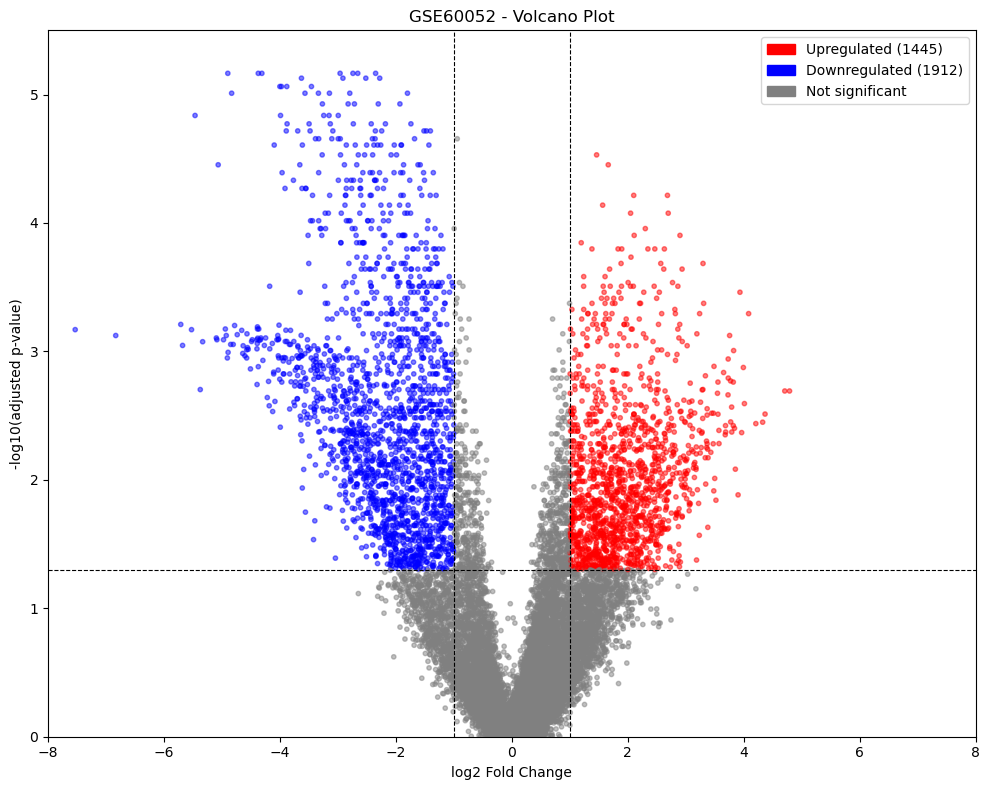

In [21]:
# Volcano plot
plt.figure(figsize=(10, 8))

colors = []
for idx, row in results_df.iterrows():
    if row['padj'] < 0.05 and row['log2FC'] >= 1:
        colors.append('red')
    elif row['padj'] < 0.05 and row['log2FC'] <= -1:
        colors.append('blue')
    else:
        colors.append('grey')

plt.scatter(results_df['log2FC'], 
            -np.log10(results_df['padj']), 
            c=colors, alpha=0.5, s=10)

plt.axhline(-np.log10(0.05), color='black', linestyle='--', linewidth=0.8)
plt.axvline(1, color='black', linestyle='--', linewidth=0.8)
plt.axvline(-1, color='black', linestyle='--', linewidth=0.8)

plt.xlabel('log2 Fold Change')
plt.ylabel('-log10(adjusted p-value)')
plt.title('GSE60052 - Volcano Plot')

plt.ylim(0, 5.5)
plt.xlim(-8, 8)

legend = [Patch(color='red', label=f'Upregulated ({(sig_degs["log2FC"] > 0).sum()})'),
          Patch(color='blue', label=f'Downregulated ({(sig_degs["log2FC"] < 0).sum()})'),
          Patch(color='grey', label='Not significant')]
plt.legend(handles=legend)

plt.tight_layout()
plt.savefig('./figures/GSE60052_volcano.png', dpi=150)
plt.show()